In [98]:
import os
import sys
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [52]:
inputs_dir = Path("../1_inputs/")
outputs_dir = Path("../3_outputs/")


In [53]:
# import allele collection file

allele_collection_df = pd.read_csv(outputs_dir / "varchamp_consolidated_alleles_clinvar_gnomad.tsv", sep="\t")
allele_collection_df

,orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,...,clinvar_nt_change,clinvar_aa_change,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,chrom,ref,alt,varid,gnomad_af
0,2,GBA,160G>C,Val54Leu,ENSG00000177628,1,155240033,NC_000001.11:155240033:C:G,ALE0000584,CCSBVarC000001,...,NaN,NaN,NaN,NaN,NaN,chr1,G,C,1-155240033-G-C,NaN
1,2,GBA,670C>T,Leu224Phe,ENSG00000177628,1,155238225,NC_000001.11:155238225:G:A,ALE00000002,CCSBVarC000002,...,NaN,NaN,NaN,NaN,NaN,chr1,C,T,1-155238225-C-T,NaN
2,2,GBA,887G>A,Arg296Gln,ENSG00000177628,1,155237453,NC_000001.11:155237453:C:T,ALE00000003,CCSBVarC000003,...,887G>A,Arg296Gln,NM_000157.4,2.0,1_Pathogenic,chr1,G,A,1-155237453-G-A,NaN
3,2,GBA,1448T>C,Leu483Pro,ENSG00000177628,1,155235252,NC_000001.11:155235252:A:G,ALE00000004,CCSBVarC000004,...,1448T>C,Leu483Pro,NM_000157.4,2.0,1_Pathogenic,chr1,T,C,1-155235252-T-C,NaN
4,25,SLC9A3R1,328C>G,Leu110Val,ENSG00000109062,17,74749174,NC_000017.11:74749174:C:G,ALE00000005,CCSBVarC000005,...,328C>G,Leu110Val,NM_004252.5,2.0,2_Benign,chr17,C,G,17-74749174-C-G,0.026302
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8483,8999,TTR,355G>A,Asp119Asn,ENSG00000118271,18,31598586,NC_000018.10:31598586:G:A,ALE00008468,CCSBVarC008481,...,355G>A,Asp119Asn,NM_000371.4,1.0,3_Conflicting,chr18,G,A,18-31598586-G-A,0.000079
8484,7323,PMP22,152A>G,His51Arg,ENSG00000109099,17,15259120,NC_000017.11:15259120:T:C,ALE00008469,CCSBVarC008466,...,152A>G,His51Arg,NM_000304.4,1.0,3_Conflicting,chr17,A,G,17-15259120-A-G,NaN
8485,2651,CLN6,89G>C,Gly30Ala,ENSG00000128973,15,68218645,NC_000015.10:68218645:C:G,ALE00008470,CCSBVarC008436,...,89G>C,Gly30Ala,NM_017882.3,1.0,2_Benign,chr15,G,C,15-68218645-G-C,NaN
8486,7323,PMP22,403G>A,Ala135Thr,ENSG00000109099,17,15230997,NC_000017.11:15230997:C:T,ALE00008471,CCSBVarC008467,...,403G>A,Ala135Thr,NM_000304.4,2.0,2_Benign,chr17,G,A,17-15230997-G-A,NaN


In [54]:
allele_collection_df.collection.unique()

array(['RC4', 'CEGS2', 'Edgotyping3', 'BRUH'], dtype=object)

In [55]:
# inspect columns

allele_collection_df.columns

Index(['orf_id', 'symbol', 'nt_change', 'aa_change', 'ensembl_gene_id', 'chr',
       'chr_pos_38', 'spdi', 'ccsb_allele_id', 'ccsb_mutation_id',
       'mutation_id_rc4', 'mutation_id_cegs2', 'mutation_id_edgotyping3',
       'entry_plate', 'entry_well', 'collection', 'sequence', '#AlleleID',
       'Type', 'Name', 'GeneID', 'GeneSymbol', 'HGNC_ID',
       'ClinicalSignificance', 'ClinSigSimple', 'LastEvaluated', 'RS# (dbSNP)',
       'nsv/esv (dbVar)', 'RCVaccession', 'PhenotypeIDS', 'PhenotypeList',
       'Origin', 'OriginSimple', 'Assembly', 'ChromosomeAccession',
       'Chromosome', 'Start', 'Stop', 'Cytogenetic', 'ReviewStatus',
       'NumberSubmitters', 'Guidelines', 'TestedInGTR', 'OtherIDs',
       'SubmitterCategories', 'VariationID', 'PositionVCF',
       'ReferenceAlleleVCF', 'AlternateAlleleVCF', 'SomaticClinicalImpact',
       'SomaticClinicalImpactLastEvaluated', 'ReviewStatusClinicalImpact',
       'Oncogenicity', 'OncogenicityLastEvaluated', 'ReviewStatusOncogenicit

In [56]:
# explore PhenotypeIDS

allele_collection_df['PhenotypeIDS'].value_counts()

PhenotypeIDS
MedGen:CN517202                                                                                                                                                                                                                                                                                                                   249
MedGen:C3661900                                                                                                                                                                                                                                                                                                                   170
-                                                                                                                                                                                                                                                                                                                                  96
MedGen:CN

In [57]:
# extract omim data from PhenotypeIDS and store in into OMIM_IDs column

allele_collection_df['OMIM_IDs'] = allele_collection_df['PhenotypeIDS'].str.extractall(r'OMIM:(\d+)')[0].groupby(level=0).apply(list)

allele_collection_df

,orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,...,clinvar_aa_change,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,chrom,ref,alt,varid,gnomad_af,OMIM_IDs
0,2,GBA,160G>C,Val54Leu,ENSG00000177628,1,155240033,NC_000001.11:155240033:C:G,ALE0000584,CCSBVarC000001,...,NaN,NaN,NaN,NaN,chr1,G,C,1-155240033-G-C,NaN,NaN
1,2,GBA,670C>T,Leu224Phe,ENSG00000177628,1,155238225,NC_000001.11:155238225:G:A,ALE00000002,CCSBVarC000002,...,NaN,NaN,NaN,NaN,chr1,C,T,1-155238225-C-T,NaN,NaN
2,2,GBA,887G>A,Arg296Gln,ENSG00000177628,1,155237453,NC_000001.11:155237453:C:T,ALE00000003,CCSBVarC000003,...,Arg296Gln,NM_000157.4,2.0,1_Pathogenic,chr1,G,A,1-155237453-G-A,NaN,"[608013, 230800, 230900, 231000, 231005, 16860..."
3,2,GBA,1448T>C,Leu483Pro,ENSG00000177628,1,155235252,NC_000001.11:155235252:A:G,ALE00000004,CCSBVarC000004,...,Leu483Pro,NM_000157.4,2.0,1_Pathogenic,chr1,T,C,1-155235252-T-C,NaN,"[230900, 230800, 231000, 168600, 608013, 23080..."
4,25,SLC9A3R1,328C>G,Leu110Val,ENSG00000109062,17,74749174,NC_000017.11:74749174:C:G,ALE00000005,CCSBVarC000005,...,Leu110Val,NM_004252.5,2.0,2_Benign,chr17,C,G,17-74749174-C-G,0.026302,[612287]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8483,8999,TTR,355G>A,Asp119Asn,ENSG00000118271,18,31598586,NC_000018.10:31598586:G:A,ALE00008468,CCSBVarC008481,...,Asp119Asn,NM_000371.4,1.0,3_Conflicting,chr18,G,A,18-31598586-G-A,0.000079,[105210]
8484,7323,PMP22,152A>G,His51Arg,ENSG00000109099,17,15259120,NC_000017.11:15259120:T:C,ALE00008469,CCSBVarC008466,...,His51Arg,NM_000304.4,1.0,3_Conflicting,chr17,A,G,17-15259120-A-G,NaN,NaN
8485,2651,CLN6,89G>C,Gly30Ala,ENSG00000128973,15,68218645,NC_000015.10:68218645:C:G,ALE00008470,CCSBVarC008436,...,Gly30Ala,NM_017882.3,1.0,2_Benign,chr15,G,C,15-68218645-G-C,NaN,NaN
8486,7323,PMP22,403G>A,Ala135Thr,ENSG00000109099,17,15230997,NC_000017.11:15230997:C:T,ALE00008471,CCSBVarC008467,...,Ala135Thr,NM_000304.4,2.0,2_Benign,chr17,G,A,17-15230997-G-A,NaN,[162500]


In [69]:
allele_collection_gene_list = allele_collection_df['symbol'].dropna().unique().tolist()
allele_collection_gene_list

['GBA',
 'SLC9A3R1',
 'MYD88',
 'ACTA2',
 'FOXA3',
 'RFX5',
 'HYLS1',
 'ALDOA',
 'CTH',
 'PEPD',
 'MVK',
 'ABHD5',
 'GALT',
 'TYROBP',
 'OXCT1',
 'CBS',
 'SERPING1',
 'STAR',
 'CLU',
 'BPGM',
 'SEMA4A',
 'ETFA',
 'CD40',
 'SPINT2',
 'AGA',
 'PRNP',
 'PTGS2',
 'MSX2',
 'TFPI',
 'RPIA',
 'CYB5A',
 'A4GALT',
 'SCO1',
 'BCHE',
 'PLOD1',
 'SLC25A38',
 'PCCB',
 'ASAH1',
 'LBR',
 'ARL11',
 'MAT1A',
 'PCCA',
 'MMADHC',
 'SULT1A1',
 'PSAT1',
 'TPP1',
 'YARS1',
 'CDK5R1',
 'BMP4',
 'PRKAG2',
 'LFNG',
 'ETNPPL',
 'GJA1',
 'GAD1',
 'AQP1',
 'BBS10',
 'CRYM',
 'PIP4K2A',
 'LGI1',
 'OMG',
 'PTS',
 'PAK5',
 'SGCE',
 'GPAM',
 'CALR3',
 'HLA-G',
 'LARS2',
 'TMEM67',
 'PRKN',
 'MTM1',
 'ERAP1',
 'CRISP2',
 'ESR2',
 'GLE1',
 'RASA1',
 'ZFYVE27',
 'KCNJ13',
 'MLC1',
 'THAP1',
 'PNKD',
 'KIF6',
 'ALG6',
 'TGIF1',
 'CDKN1B',
 'ARL6',
 'LIG4',
 'MBTPS2',
 'CBLB',
 'LHFPL5',
 'KCNE1',
 'KCNE1B',
 'SERPIND1',
 'DDX20',
 'MFSD8',
 'TRIM37',
 'LRAT',
 'PHYH',
 'CUL4B',
 'KRT8',
 'LIPA',
 'EBP',
 'CHMP2B',
 'ILK'

In [59]:
# Load OMIM data

omim_df = pd.read_csv(inputs_dir / 'mimTitles.txt', sep="\t", skiprows=2)
omim_df.dropna(subset=['MIM Number'], inplace=True)
omim_df['MIM Number'] = omim_df['MIM Number'].astype(int)
omim_df['disease_name'] = omim_df['Preferred Title; symbol'].apply(lambda x: x if x != x else x.split(';')[0])
omim_df['Symbol'] = omim_df['Preferred Title; symbol'].apply(lambda x: x if x != x else x.split(';')[-1] if ';' in x else None)
omim_df.drop(columns=['Preferred Title; symbol'], inplace=True)
omim_df

,# Prefix,MIM Number,Alternative Title(s); symbol(s),Included Title(s); symbols,disease_name,Symbol
0,NaN,100050,NaN,NaN,"AARSKOG SYNDROME, AUTOSOMAL DOMINANT",None
1,Percent,100070,"ANEURYSM, ABDOMINAL AORTIC; AAA;; ABDOMINAL AO...",NaN,"AORTIC ANEURYSM, FAMILIAL ABDOMINAL, 1",AAA1
2,Number Sign,100100,"ABDOMINAL MUSCLES, ABSENCE OF, WITH URINARY TR...",NaN,PRUNE BELLY SYNDROME,PBS
3,NaN,100200,NaN,NaN,ABDUCENS PALSY,None
4,Number Sign,100300,"AOS;; ABSENCE DEFECT OF LIMBS, SCALP, AND SKUL...","APLASIA CUTIS CONGENITA, CONGENITAL HEART DEFE...",ADAMS-OLIVER SYNDROME 1,AOS1
...,...,...,...,...,...,...
29097,Asterisk,621148,NaN,NaN,CHROMOSOME 16 OPEN READING FRAME 89,C16ORF89
29098,Asterisk,621149,LEG1,NaN,CHROMOSOME 6 OPEN READING FRAME 58,C6ORF58
29099,Number Sign,621150,NaN,NaN,NEURODEVELOPMENTAL DISORDER WITH THIN CORPUS C...,NEDTCHAL
29100,Asterisk,621151,KYNURENINE FORMAMIDASE; KF; KFA,NaN,ARYLFORMAMIDASE,AFMID


In [60]:
omim_dict = omim_df.set_index('MIM Number')['disease_name'].to_dict()
omim_dict

{100050: 'AARSKOG SYNDROME, AUTOSOMAL DOMINANT',
 100070: 'AORTIC ANEURYSM, FAMILIAL ABDOMINAL, 1',
 100100: 'PRUNE BELLY SYNDROME',
 100200: 'ABDUCENS PALSY',
 100300: 'ADAMS-OLIVER SYNDROME 1',
 100500: 'MOVED TO 200150',
 100600: 'ACANTHOSIS NIGRICANS',
 100640: 'ALDEHYDE DEHYDROGENASE 1 FAMILY, MEMBER A1',
 100650: 'ALDEHYDE DEHYDROGENASE 2 FAMILY',
 100660: 'ALDEHYDE DEHYDROGENASE, FAMILY 3, SUBFAMILY A, MEMBER 1',
 100670: 'ALDEHYDE DEHYDROGENASE 1 FAMILY, MEMBER B1',
 100675: 'ACETAMINOPHEN METABOLISM',
 100678: 'ACETYL-CoA ACETYLTRANSFERASE 2',
 100680: 'MOVED TO 100740',
 100690: 'CHOLINERGIC RECEPTOR, NICOTINIC, ALPHA POLYPEPTIDE 1',
 100700: 'ACHARD SYNDROME',
 100710: 'CHOLINERGIC RECEPTOR, NICOTINIC, BETA POLYPEPTIDE 1',
 100720: 'CHOLINERGIC RECEPTOR, NICOTINIC, DELTA POLYPEPTIDE',
 100725: 'CHOLINERGIC RECEPTOR, NICOTINIC, EPSILON POLYPEPTIDE',
 100730: 'CHOLINERGIC RECEPTOR, NICOTINIC, GAMMA POLYPEPTIDE',
 100735: 'MOVED TO 142445',
 100740: 'ACETYLCHOLINESTERASE',
 100

In [61]:
# import rare disease module file
# from https://www.nature.com/articles/s41467-021-26674-1
# supplementary data 5

rd_df = pd.read_csv(inputs_dir / 'rare_disease_modules.txt', sep='\t')

rd_df

,name,all_genes
0,Rare genetic vascular disease,SLC2A10;MYH11;COL3A1;COL5A1;TGFBR2;FBN1;SMAD3;...
1,Rare genetic systemic or rheumatologic disease,PSMB8;SAMHD1;RNASEH2A;RNASEH2B;RNASEH2C;ADAR;T...
2,Rare genetic eye disease,NF1;RB1;MYCN;PITX2;SCO2;P3H2;LRPAP1;KERA;PIK3R...
3,Rare genetic gynecological and obstetrical dis...,H6PD;HSD11B1;ESR1;GNAS;KISS1R;MKRN3;DLK1;CYP19...
4,Rare genetic immune disease,WAS;WIPF1;FOXN1;DKC1;TERT;TERC;TINF2;NOP10;NHP...
5,Rare genetic cardiac disease,TTN;PKP2;RYR2;TGFB3;DSC2;DSG2;DSP;JUP;LDB3;LMN...
6,Rare genetic renal disease,HBB;HBA2;HBA1;RAD51;MAD2L2;BRCA1;XRCC2;RFWD3;B...
7,Rare genetic developmental defect during embry...,ATM;KITLG;SNAI2;SOX10;MITF;EDNRB;PAX3;ACVRL1;S...
8,Rare genetic bone disease,AGA;SUMF1;MANBA;FUCA1;GNPTAB;GUSB;CTSA;ARSB;ID...
9,Rare genetic odontologic disease,GINGF2;SOS1;REST;BRF1;PTH1R;FAM83H;SLC24A4;ITG...


In [62]:
rd_dict = {rd:gene_list.split(';') for rd, gene_list in zip(rd_df['name'], rd_df['all_genes'])}
rd_dict

{'Rare genetic vascular disease': ['SLC2A10',
  'MYH11',
  'COL3A1',
  'COL5A1',
  'TGFBR2',
  'FBN1',
  'SMAD3',
  'NKX2-5',
  'GATA5',
  'NOTCH1',
  'SMAD6',
  'ACTA2',
  'TGFBR1',
  'FOXE3',
  'LOX',
  'MAT2A',
  'ELN',
  'TGFB3',
  'MYLK',
  'PRKG1',
  'MFAP5',
  'TGFB2'],
 'Rare genetic systemic or rheumatologic disease': ['PSMB8',
  'SAMHD1',
  'RNASEH2A',
  'RNASEH2B',
  'RNASEH2C',
  'ADAR',
  'TREX1',
  'IFIH1',
  'ACP5',
  'ISG15',
  'C1QA',
  'C4A',
  'DNASE1L3',
  'PRKCD',
  'DNASE1',
  'ADA2',
  'TMEM173',
  'USP18',
  'DDX58',
  'POLA1',
  'TTC37',
  'SKIV2L',
  'APOA2',
  'APP',
  'B2M',
  'GSN',
  'ITM2B',
  'FGA',
  'APOA1',
  'LYZ',
  'CST3',
  'TTR',
  'RBCK1',
  'RNF31',
  'PLCG2',
  'MEFV',
  'NLRP12',
  'NLRC4',
  'OTULIN',
  'TNFRSF1A',
  'MVK',
  'NLRP3',
  'SLC39A13',
  'P4HA1',
  'CHST14',
  'DSE',
  'COL1A1',
  'COL1A2',
  'FLNA',
  'TNXB',
  'PLOD1',
  'COL3A1',
  'COL5A1',
  'ADAMTS2',
  'FKBP14',
  'C1S',
  'C1R',
  'B4GALT7',
  'B3GALT6',
  'ZNF469',
  'P

In [71]:
# create a dict for each disease module with the genes found in our allele collection

disease_module_dict = {rd: [gene for gene in gene_list if gene in allele_collection_gene_list] for rd, gene_list in rd_dict.items()}
disease_module_dict

{'Rare genetic vascular disease': ['SLC2A10',
  'TGFBR2',
  'SMAD3',
  'NKX2-5',
  'SMAD6',
  'ACTA2',
  'TGFBR1'],
 'Rare genetic systemic or rheumatologic disease': ['SAMHD1',
  'RNASEH2C',
  'TREX1',
  'C1QA',
  'B2M',
  'FGA',
  'APOA1',
  'LYZ',
  'CST3',
  'TTR',
  'TNFRSF1A',
  'MVK',
  'SLC39A13',
  'CHST14',
  'PLOD1',
  'C1S',
  'B4GALT7',
  'TGFBR2',
  'SMAD3',
  'TGFBR1',
  'ACTA2'],
 'Rare genetic eye disease': ['MYCN',
  'PITX2',
  'SCO2',
  'P3H2',
  'KERA',
  'PIK3R1',
  'NMNAT1',
  'RDH12',
  'RPE65',
  'CEP290',
  'AIPL1',
  'TULP1',
  'CRX',
  'IMPDH1',
  'KCNJ13',
  'LRAT',
  'RPGR',
  'CNGA3',
  'ATF6',
  'CYBB',
  'NCF1',
  'NCF2',
  'PHC1',
  'GFAP',
  'GBA',
  'PNKP',
  'FXN',
  'ATM',
  'CHN1',
  'MAFB',
  'APTX',
  'PLP1',
  'SETX',
  'GLB1',
  'TMEM216',
  'TMEM138',
  'TMEM67',
  'ARL13B',
  'INPP5E',
  'CEP41',
  'HYLS1',
  'KIF7',
  'NPC2',
  'MAPT',
  'NDUFA13',
  'SDHA',
  'SLC19A3',
  'SURF1',
  'COX15',
  'NDUFS1',
  'NDUFS3',
  'NDUFS7',
  'NDUFV1',
 

In [82]:
# to table with gene count

dict_for_table = {rd:gene_joined for rd, gene_list in disease_module_dict.items() for gene_joined in [';'.join(gene_list)]}

disease_module_df = pd.DataFrame(list(dict_for_table.items()), columns=['disease_module', 'genes'])

disease_module_df.columns = ['disease_module', 'genes']
disease_module_df['gene_count'] = disease_module_df['genes'].str.split(';').str.len()
disease_module_df

,disease_module,genes,gene_count
0,Rare genetic vascular disease,SLC2A10;TGFBR2;SMAD3;NKX2-5;SMAD6;ACTA2;TGFBR1,7
1,Rare genetic systemic or rheumatologic disease,SAMHD1;RNASEH2C;TREX1;C1QA;B2M;FGA;APOA1;LYZ;C...,21
2,Rare genetic eye disease,MYCN;PITX2;SCO2;P3H2;KERA;PIK3R1;NMNAT1;RDH12;...,367
3,Rare genetic gynecological and obstetrical dis...,HSD11B1;ESR1;GNAS;CYP19A1;SEMA3E;HBB;RBM28;BBS...,67
4,Rare genetic immune disease,DKC1;TINF2;NOP10;NHP2;WRAP53;CCBE1;STIM1;IKBKG...,107
5,Rare genetic cardiac disease,PKP2;JUP;LDB3;LMNA;TMEM43;CTNNA3;ACTC1;TNNT2;T...,106
6,Rare genetic renal disease,HBB;HBA2;HBA1;BRCA1;XRCC2;BRIP1;FANCC;FANCD2;F...,156
7,Rare genetic developmental defect during embry...,ATM;KITLG;SOX10;MITF;EDNRB;PAX3;ACVRL1;SMAD4;G...,526
8,Rare genetic bone disease,AGA;FUCA1;GNPTAB;GUSB;CTSA;IDS;GALNS;GLB1;GNPT...,171
9,Rare genetic odontologic disease,PTH1R;GPR68;AXIN2;EDA;FGFR1;WNT10A;MSX1;PAX9;S...,12


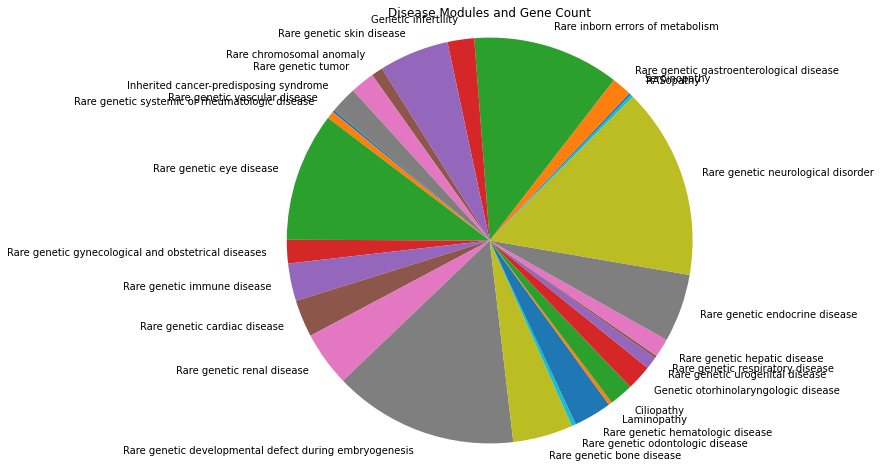

In [100]:
plt.figure(figsize=(8, 8))
plt.pie(disease_module_df['gene_count'], labels=disease_module_df['disease_module'], startangle=140)
plt.title('Disease Modules and Gene Count')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

In [83]:
disease_module_df.to_csv(outputs_dir / 'disease_modules_to_genes.tsv', sep='\t', index=False)

In [91]:
# Some genes are associated with more than 1 module
# table to plot the number of genes associated with 1 module, 2 modules, 3 modules, etc.

gene_module_dict = {}

for _, row in disease_module_df.iterrows():
    gene_list = row['genes'].split(';')
    for gene in gene_list:
        if gene in gene_module_dict:
            gene_module_dict[gene] += 1
        else:
            gene_module_dict[gene] = 1
            
gene_module_df = pd.DataFrame(list(gene_module_dict.items()), columns=['gene', 'module_count'])
gene_module_df

,gene,module_count
0,SLC2A10,3
1,TGFBR2,7
2,SMAD3,2
3,NKX2-5,6
4,SMAD6,2
...,...,...
1271,HABP2,1
1272,MSR1,1
1273,PMS1,2
1274,MLH3,2


In [95]:
module_count = gene_module_df.module_count.value_counts().sort_index()
module_counts_df = pd.DataFrame(module_count)
module_counts_df.to_csv(outputs_dir / 'module_counts.tsv', sep='\t', index=False)

<Axes: xlabel='module_count'>

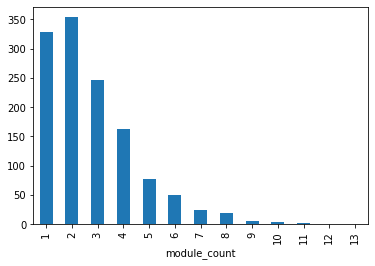

In [96]:
gene_module_df.module_count.value_counts().sort_index().plot(kind='bar')